<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/14_IoT_IIoT_Attack_Detection/VQC_IoTAnomalyDetection_Chowdhury2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQC and the UU† circuit for IoT anomaly detection: Chowdhury et al. (2025) step by step

**Paper.** Sajid Ahmed Chowdhury, Shaikh Faiyaz Karim, Md. Shahriar Islam Bhuiyan, Ali Abir Shuvro, Md. Sakhawat Hossen,
*Quantum Machine Learning for Anomaly Detection in IoT Devices*, 2025 5th International Conference on AI-ML-Systems
(AIMLSystems 2025), IEEE. DOI [10.1109/AIMLSYSTEMS67835.2025.11331191](https://doi.org/10.1109/AIMLSYSTEMS67835.2025.11331191).

**What this notebook does.** It rebuilds the paper's two quantum models in Qiskit: a **variational quantum circuit (VQC)**
trained with COBYLA, and the **UU† circuit**, a state-overlap classifier that compares each record with k-means centroids.
Both are run on the two of the paper's five datasets that can be downloaded without a login and that carry real attack
labels (**KDDCup99** and the **IoT Fridge** telemetry of TON_IoT), next to classical baselines on exactly the same inputs.
At the end it prints the paper's numbers next to ours and gives a verdict for every claim it can check.

**How to run.** Open in Colab, choose a CPU runtime and press *Runtime -> Run all*. `FAST_MODE = True` (default) takes
a few minutes; `FAST_MODE = False` uses the larger budgets documented in the configuration cell. Nothing needs to be uploaded.

**What you get.** Dataset plots, drawings of the circuits that are actually executed, a table of accuracy / balanced accuracy /
F1 for every model and dataset (mean and standard deviation over several seeds), confusion matrices, VQC loss curves, a
side-by-side comparison with the paper's Tables II to IV and a critical reading of the paper.

## The paper in one page

| Item | What the paper says |
|---|---|
| Problem | Detect anomalies / attacks in IoT sensor and network data with quantum machine learning (QML), motivated by the cost of classical models (LSTM autoencoder) on big IoT data |
| Decision | Normal versus anomalous record (binary, accuracy is the only metric, Eq. in Section III-C) |
| Quantum models | (1) **VQC**: feature map + ansatz + parity decoding, optimiser **COBYLA**, Qiskit. (2) **UU†** circuit: encode the record with a unitary `U(x)`, encode a threshold / centroid with `U†(c)`, read the probability of the all-zero outcome (Born rule), thresholds from **k-means centroids**; 100 shots |
| Encoding | Angle encoding and (customised) Pauli feature maps; features scaled to [0, π] |
| Preprocessing | Label encoding, mutual-information feature selection and PCA (the number of qubits limits the features), scaling |
| Datasets (Table I) | KDDCup99 (494,020 x 42), Environmental Sensor Telemetry (405,184 x 9), IoT Fridge (59,945 x 6), TWTDUS Texas wind turbine (8,760 x 6), anoML-IoT (6,558 x 6) |
| Claims | Table II, VQC accuracy: KDDCup99 80.33 % (10 iterations), anoML-IoT 92.00 % (60), Env. Sensor 65.65 % (10), TWTDUS 73.00 % (25), IoT Fridge 58.00 % (35). Table III, UU† accuracy (100 shots): 83.36 / 82.03 / 96.08 (Env. Sensor) / 99.62 (TWTDUS) / 55.33 %. Table IV, classical LSTM autoencoder: 97.37 / 94.94 / 94.99 / 94.96 / 84.79 %. Quantum models fall short of the classical ones but "may scale better" |

### Which datasets can be run here

| Dataset | Status in this notebook |
|---|---|
| KDDCup99 | **Run.** The 10 % file (494,021 records) is the paper's 494,020 x 42 |
| IoT Fridge | **Run**, with a substitute size: the public labelled *train-test* subset of TON_IoT Fridge has 39,944 records (the paper reports 59,945 from the full telemetry file). Same sensor, same attacks |
| Environmental Sensor Telemetry | **Not run.** The Kaggle file has no anomaly / attack label (columns: ts, device, co, humidity, light, lpg, motion, smoke, temp), so no accuracy can be computed without inventing labels |
| anoML-IoT, TWTDUS | **Not run.** Only on Kaggle / the authors' pages without a public mirror reachable by script; the notebook does not substitute unrelated data |

Their claims are therefore listed as "cannot be checked" at the end.

## What follows the paper and what had to be chosen

The paper does not give qubit counts, sample sizes, ansatz depth, train/test split, seeds or the exact feature maps. Everything marked
`# CHOICE:` in the code is ours.

| Item | Paper | This notebook |
|---|---|---|
| Qubits | not stated ("limited by the number of qubits") | 4 (one per PCA component); 2 for the sensor-only diagnostic (only two features exist) |
| Feature selection | mutual information + PCA | `mutual_info_classif` top 8 -> StandardScaler -> PCA(4) -> MinMaxScaler to [0, π]; all fitted on the training split only |
| Class balance / split | not stated | natural class ratio kept (stratified random draw), `N_TRAIN` / `N_TEST` records per seed, disjoint |
| Feature map | angle encoding + (customised) PauliFeatureMap | `pauli_feature_map(n, reps=2, paulis=["Z","ZZ"], entanglement="linear")` for VQC and UU†; plain RY angle encoding as a UU† variant |
| VQC ansatz | not stated | `real_amplitudes(n, reps=3, entanglement="linear")`, measured in the computational basis, parity decoding (Qiskit `VQC` default) |
| VQC optimiser / iterations | COBYLA, 10 / 35 iterations (Table II) | COBYLA with exactly those budgets; an extended budget in the full run |
| Shots / simulator | UU†: 100 shots, Qiskit simulators | UU†: 100 shots; VQC: 1024 shots; Aer state-vector simulator with shots drawn from the exact outcome distribution (see the note before the UU† check) |
| UU† centroids | "k-means centroids" | k-means with 2 clusters on the training angles; each cluster takes the majority training label; the class of the centroid with the larger all-zero probability is predicted. Class-mean centroids as a variant |
| Classical comparison | LSTM autoencoder (Table IV, from the literature) | RandomForest and SVC(rbf) on the identical 4 inputs and on all features, a majority-class baseline, and a small scikit-learn MLP autoencoder trained on normal records only (no TensorFlow; not an LSTM) |
| Repetitions | one number per cell | `N_SEEDS` seeds, mean and standard deviation |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


## Configuration

Every tunable constant lives in this one cell. `FAST_MODE = True` is a class demo; `FAST_MODE = False` uses larger samples,
more seeds and an extra VQC run with a longer COBYLA budget (see the comments for the runtime of each).

In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: a few minutes on a CPU. False: larger samples, more seeds, longer VQC budget (about 30 to 60 min)

SEED      = 42              # CHOICE: the paper gives no seed
N_QUBITS  = 4               # CHOICE: the paper does not state the qubit count
MI_TOP_K  = 8               # CHOICE: features kept by mutual information before PCA

if FAST_MODE:
    N_TRAIN, N_TEST, N_SEEDS = 300, 600, 2      # CHOICE: records per seed (the paper does not say)
    VQC_EXTRA_ITERS = 0                         # no extra long-budget VQC run
else:
    N_TRAIN, N_TEST, N_SEEDS = 600, 2000, 3
    VQC_EXTRA_ITERS = 100                       # additional VQC run with this COBYLA budget

VQC_ITERS    = {"KDDCup99": 10, "IoT Fridge": 35, "IoT Fridge (sensor only)": 35}   # paper Table II (COBYLA iterations)
VQC_FM_REPS  = 2            # CHOICE: Pauli feature-map repetitions
VQC_ANSATZ_REPS = 3         # CHOICE: RealAmplitudes repetitions
SHOTS_VQC    = 1024         # CHOICE: shots of the sampler inside the VQC
SHOTS_UU     = 100          # paper Table III: 100 shots
AE_PERCENTILE = 95          # CHOICE: autoencoder threshold = this percentile of the training-normal reconstruction error

DATA_DIR  = "data"          # cache folder for the downloads
IBM_TOKEN = ""              # not used: everything runs on the Aer simulator (the paper also used simulators)

In [3]:
import os, io, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import pauli_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
T_NOTEBOOK_START = time.time()

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-aer", qiskit_aer.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| N_TRAIN/N_TEST =", N_TRAIN, "/", N_TEST, "| seeds =", N_SEEDS, "| extra VQC iters =", VQC_EXTRA_ITERS)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | N_TRAIN/N_TEST = 600 / 2000 | seeds = 3 | extra VQC iters = 100


## 1. Loading the two datasets

**KDDCup99** (Tavallaee et al. / KDD-99 competition). The 10 % file holds 494,021 connection records with 41 features and a
label that is either `normal` or the name of one of 22 attacks. It is downloaded from scikit-learn's figshare mirror, with the
original UCI address and `sklearn.datasets.fetch_kddcup99` as fallbacks. Like the paper we keep **all records, duplicates
included**; about 80 % of them are attacks.

**IoT Fridge** (TON_IoT telemetry, Alsaedi et al. 2020; the paper's reference [25]). The public Hugging Face mirror
`SilverDragon9/UNSW_TON-IoT_Train_Test_IoT_Datasets` holds the labelled *train-test* subset of the fridge sensor: date, time,
`fridge_temperature`, `temp_condition` (high / low), a binary `label` and the attack `type` (normal, ddos, backdoor,
injection, password, ransomware, xss). This dataset is not gated; the token handling below is only used if a mirror asks for it.
If you ever hit a gated dataset, add your own `HF_TOKEN` under *Colab -> Secrets*; the code never prints or stores it.

In [4]:
import requests

HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

KDD_URLS = ["https://ndownloader.figshare.com/files/5976042",                             # scikit-learn's mirror of the 10 % file
            "http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz"]        # original UCI location
KDD_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
               "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
               "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
               "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
               "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
               "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
               "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label"]
KDD_CAT = ["protocol_type", "service", "flag"]
FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop"]: FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep"]: FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy"]: FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl"]: FAMILY[a] = "U2R"

def load_kdd():
    path = os.path.join(DATA_DIR, "kddcup.data_10_percent.gz")
    if not os.path.exists(path):
        ok = False
        for url in KDD_URLS:
            try:
                r = requests.get(url, timeout=180); r.raise_for_status()
                open(path, "wb").write(r.content); ok = True; print("downloaded KDD99 from", url.split("/")[2]); break
            except Exception as e:
                print("failed:", url, type(e).__name__)
        if not ok:
            raise RuntimeError("KDD99 mirrors unreachable: download kddcup.data_10_percent.gz and put it into DATA_DIR")
    return pd.read_csv(path, header=None, names=KDD_COLUMNS, compression="gzip")

def load_fridge():
    repo, fname = "SilverDragon9/UNSW_TON-IoT_Train_Test_IoT_Datasets", "Train_Test_IoT_Fridge.csv"
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        try:
            from huggingface_hub import hf_hub_download
            path = hf_hub_download(repo, fname, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)
        except Exception as e:
            print("huggingface_hub failed (", type(e).__name__, "); trying the plain URL")
            r = requests.get(f"https://huggingface.co/datasets/{repo}/resolve/main/{fname}", timeout=120); r.raise_for_status()
            open(path, "wb").write(r.content)
    return pd.read_csv(path)

t0 = time.time()
kdd_raw = load_kdd()
kdd_raw["label"] = kdd_raw["label"].str.rstrip(".")
fr_raw = load_fridge()
for c in ["date", "time", "temp_condition", "type"]:
    fr_raw[c] = fr_raw[c].astype(str).str.strip()
print(f"loaded in {time.time() - t0:.1f} s | KDD99: {kdd_raw.shape} | IoT Fridge: {fr_raw.shape}")

# ---- harmonise both into the same structure: features X, binary label y (1 = attack), plot groups, original labels ----
DATASETS = {}
kdd_raw["family"] = kdd_raw["label"].map(FAMILY).fillna("other")
DATASETS["KDDCup99"] = dict(X=kdd_raw[KDD_COLUMNS[:-1]].reset_index(drop=True), y=(kdd_raw["label"] != "normal").astype(int).values,
                            group=kdd_raw["family"].values, original=kdd_raw["label"].values, cat=KDD_CAT)

stamp = pd.to_datetime(fr_raw["date"] + " " + fr_raw["time"], format="%d-%b-%y %H:%M:%S")
fr_X = pd.DataFrame({"date": (stamp.dt.normalize() - stamp.dt.normalize().min()).dt.days,      # CHOICE: ordered label code of the date (days since first day)
                     "time": stamp.dt.hour * 3600 + stamp.dt.minute * 60 + stamp.dt.second,    # CHOICE: seconds since midnight
                     "fridge_temperature": fr_raw["fridge_temperature"],
                     "temp_condition": fr_raw["temp_condition"]})
DATASETS["IoT Fridge"] = dict(X=fr_X, y=fr_raw["label"].values, group=fr_raw["type"].values, original=fr_raw["type"].values,
                              cat=["temp_condition"])
# diagnostic: only the two sensor columns, no timestamp (see Section 3)
DATASETS["IoT Fridge (sensor only)"] = dict(X=fr_X[["fridge_temperature", "temp_condition"]].copy(), y=fr_raw["label"].values,
                                            group=fr_raw["type"].values, original=fr_raw["type"].values, cat=["temp_condition"])
for k, v in DATASETS.items():
    print(f"{k:26s} {v['X'].shape[0]:7,d} records x {v['X'].shape[1]:2d} features | attack share {v['y'].mean():.4f} | majority-class accuracy {max(v['y'].mean(), 1 - v['y'].mean()):.4f}")

loaded in 21.1 s | KDD99: (494021, 42) | IoT Fridge: (39944, 6)


KDDCup99                   494,021 records x 41 features | attack share 0.8031 | majority-class accuracy 0.8031
IoT Fridge                  39,944 records x  4 features | attack share 0.6245 | majority-class accuracy 0.6245
IoT Fridge (sensor only)    39,944 records x  2 features | attack share 0.6245 | majority-class accuracy 0.6245


## 2. Preprocessing: encoding, mutual information, PCA, angles

The paper label-encodes categorical columns, keeps the most informative features by mutual information, applies PCA because the
qubit count is small, and scales to [0, π] for angle encoding. `prepare` does exactly that, and **fits every step on the training
split only**:

1. draw `N_TRAIN` training and `N_TEST` test records (stratified, natural class ratio, disjoint, seed-dependent);
2. `OrdinalEncoder` for the categorical columns (unknown test categories get -1), constant columns dropped;
3. `mutual_info_classif` -> top `MI_TOP_K` features;
4. `StandardScaler` -> `PCA(n_components = number of qubits)`;
5. `MinMaxScaler((0, π))`, test angles clipped to [0, π].

The standardised selected features (before PCA) are also kept: classical baselines use them as the "all features" input.

In [5]:
def prepare(name, seed):
    """Sample, encode, select, scale, PCA and map to angles. Everything is fitted on the training split only."""
    ds = DATASETS[name]
    idx_tr, idx_te = train_test_split(np.arange(len(ds["y"])), train_size=N_TRAIN, test_size=N_TEST,
                                      stratify=ds["y"], random_state=seed)
    Xtr, Xte = ds["X"].iloc[idx_tr].copy(), ds["X"].iloc[idx_te].copy()
    if ds["cat"]:
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(Xtr[ds["cat"]])
        Xtr[ds["cat"]] = enc.transform(Xtr[ds["cat"]]); Xte[ds["cat"]] = enc.transform(Xte[ds["cat"]])
    names = np.array(Xtr.columns); Xtr, Xte = Xtr.values.astype(float), Xte.values.astype(float)
    ytr, yte = ds["y"][idx_tr], ds["y"][idx_te]
    keep = np.where(Xtr.std(0) > 0)[0]                                             # drop constant columns
    mi = mutual_info_classif(Xtr[:, keep], ytr, random_state=seed)
    sel = keep[np.argsort(mi)[::-1][:min(MI_TOP_K, len(keep))]]                    # CHOICE: top MI_TOP_K by mutual information
    sc = StandardScaler().fit(Xtr[:, sel]); Ftr, Fte = sc.transform(Xtr[:, sel]), sc.transform(Xte[:, sel])
    n_q = min(N_QUBITS, len(sel))
    pca = PCA(n_components=n_q, random_state=seed).fit(Ftr); Ztr, Zte = pca.transform(Ftr), pca.transform(Fte)
    mm = MinMaxScaler((0, np.pi)).fit(Ztr); Atr, Ate = mm.transform(Ztr), np.clip(mm.transform(Zte), 0, np.pi)
    return dict(name=name, seed=seed, n_q=n_q, idx_tr=idx_tr, idx_te=idx_te, ytr=ytr, yte=yte, selected=list(names[sel]),
                mi=dict(zip(names[keep], mi)), Ftr=Ftr, Fte=Fte, Ztr=Ztr, Zte=Zte, Atr=Atr, Ate=Ate,
                evr=pca.explained_variance_ratio_, group_tr=ds["group"][idx_tr], original_tr=ds["original"][idx_tr])

PREP0 = {name: prepare(name, SEED) for name in DATASETS}
for name, P in PREP0.items():
    print(f"{name:26s} qubits {P['n_q']} | train {len(P['ytr'])} (attack share {P['ytr'].mean():.3f}) | test {len(P['yte'])} (attack share {P['yte'].mean():.3f})")
    print(f"{'':26s} selected: {P['selected']}")
    print(f"{'':26s} PCA explained variance: {np.round(P['evr'], 3)} | angle range train [{P['Atr'].min():.2f}, {P['Atr'].max():.2f}], test [{P['Ate'].min():.2f}, {P['Ate'].max():.2f}]")

KDDCup99                   qubits 4 | train 600 (attack share 0.803) | test 2000 (attack share 0.803)
                           selected: ['count', 'src_bytes', 'dst_bytes', 'service', 'logged_in', 'dst_host_same_src_port_rate', 'protocol_type', 'srv_count']
                           PCA explained variance: [0.585 0.141 0.126 0.097] | angle range train [0.00, 3.14], test [0.00, 3.14]
IoT Fridge                 qubits 4 | train 600 (attack share 0.625) | test 2000 (attack share 0.625)
                           selected: ['date', 'time', 'fridge_temperature', 'temp_condition']
                           PCA explained variance: [0.462 0.25  0.249 0.038] | angle range train [0.00, 3.14], test [0.00, 3.14]
IoT Fridge (sensor only)   qubits 2 | train 600 (attack share 0.625) | test 2000 (attack share 0.625)
                           selected: ['temp_condition', 'fridge_temperature']
                           PCA explained variance: [0.923 0.077] | angle range train [0.00, 3.14], test [0

## Dataset Exploration and Visualisation

For both datasets: shape, feature names, the original label values with counts, the real class distribution, and a 2-D scatter
of **real training records coloured by their ground-truth label** (first the raw PCA coordinates, then the same coordinates scaled
to the angles [0, π] that go into the circuits). The multi-class attack labels are kept: KDDCup99 is coloured by attack family,
IoT Fridge by attack type. The third entry, *IoT Fridge (sensor only)*, shares the data of *IoT Fridge* and is only a diagnostic
(Section 7); it is plotted for completeness at the end.

KDDCup99
shape: (494021, 41) | feature names: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


original label values and counts:
smurf              280790
neptune            107201
normal              97278
back                 2203
satan                1589
ipsweep              1247
portsweep            1040
warezclient          1020
teardrop              979
pod                   264
nmap                  231
guess_passwd           53
buffer_overflow        30
land                   21
warezmaster            20
imap                   12
rootkit                10
loadmodule              9
ftp_write               8
multihop                7
phf                     4
perl                    3
spy                     2
binary label (1 = attack): {0: 97278, 1: 396743}
IoT Fridge
shape: (39944, 4) | feature names: ['date', 'time', 'fridge_temperature', 'temp_condition']
original label values and counts:
normal        15000
ddos           5000
backdoor       5000
injection      5000
password       5000
ransomware     2902
xss            2042
binary label (1 = attack): {0: 15000, 1: 2

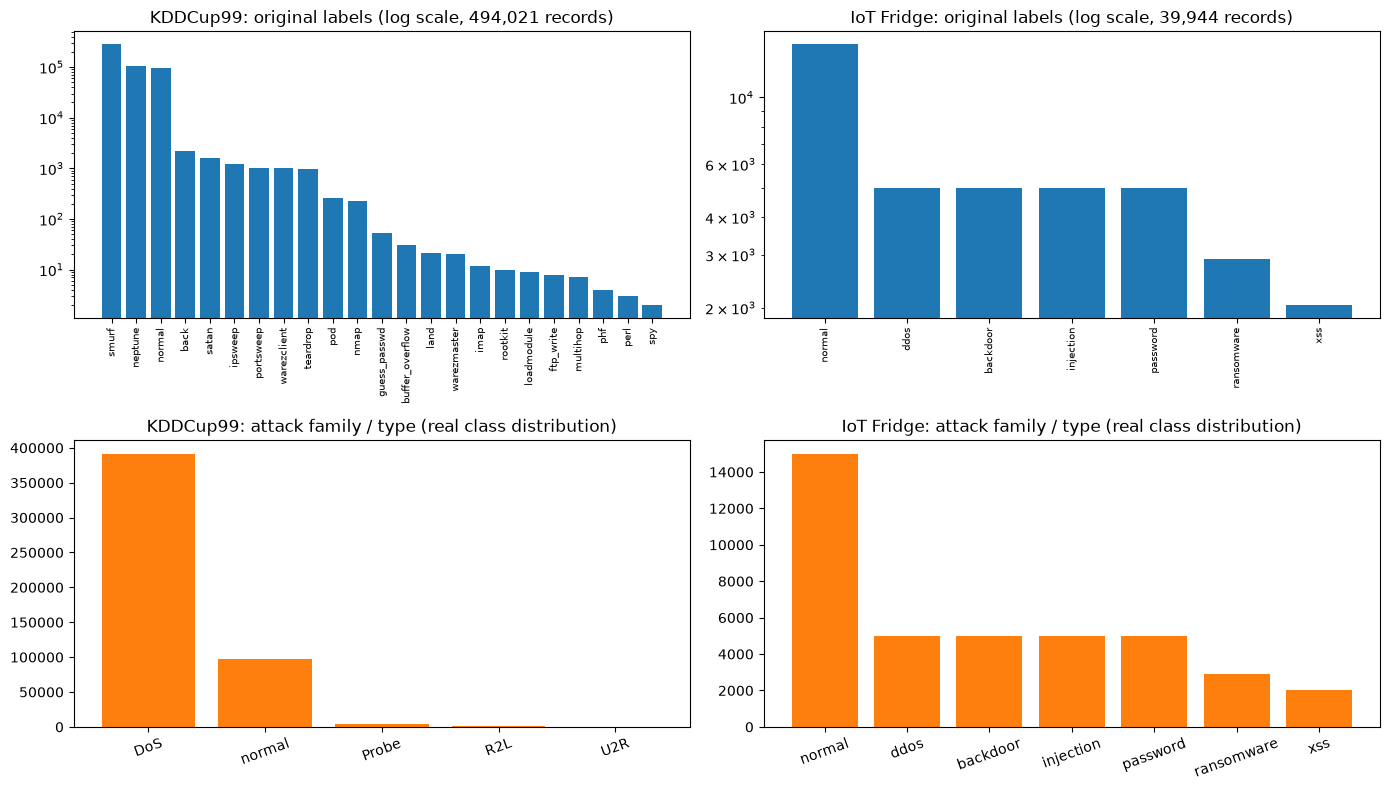

In [6]:
for name in ["KDDCup99", "IoT Fridge"]:
    ds, P = DATASETS[name], PREP0[name]
    print("=" * 100); print(name)
    print("shape:", ds["X"].shape, "| feature names:", list(ds["X"].columns))
    vc = pd.Series(ds["original"]).value_counts()
    print("original label values and counts:"); print(vc.to_string())
    print("binary label (1 = attack):", pd.Series(ds["y"]).value_counts().sort_index().to_dict())

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for j, name in enumerate(["KDDCup99", "IoT Fridge"]):
    ds = DATASETS[name]
    vc = pd.Series(ds["original"]).value_counts()
    axes[0, j].bar(vc.index, vc.values, color="tab:blue"); axes[0, j].set_yscale("log")
    axes[0, j].set_title(f"{name}: original labels (log scale, {len(ds['y']):,} records)"); axes[0, j].tick_params(axis="x", rotation=90, labelsize=7)
    vg = pd.Series(ds["group"]).value_counts()
    axes[1, j].bar(vg.index, vg.values, color="tab:orange")
    axes[1, j].set_title(f"{name}: attack family / type (real class distribution)"); axes[1, j].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

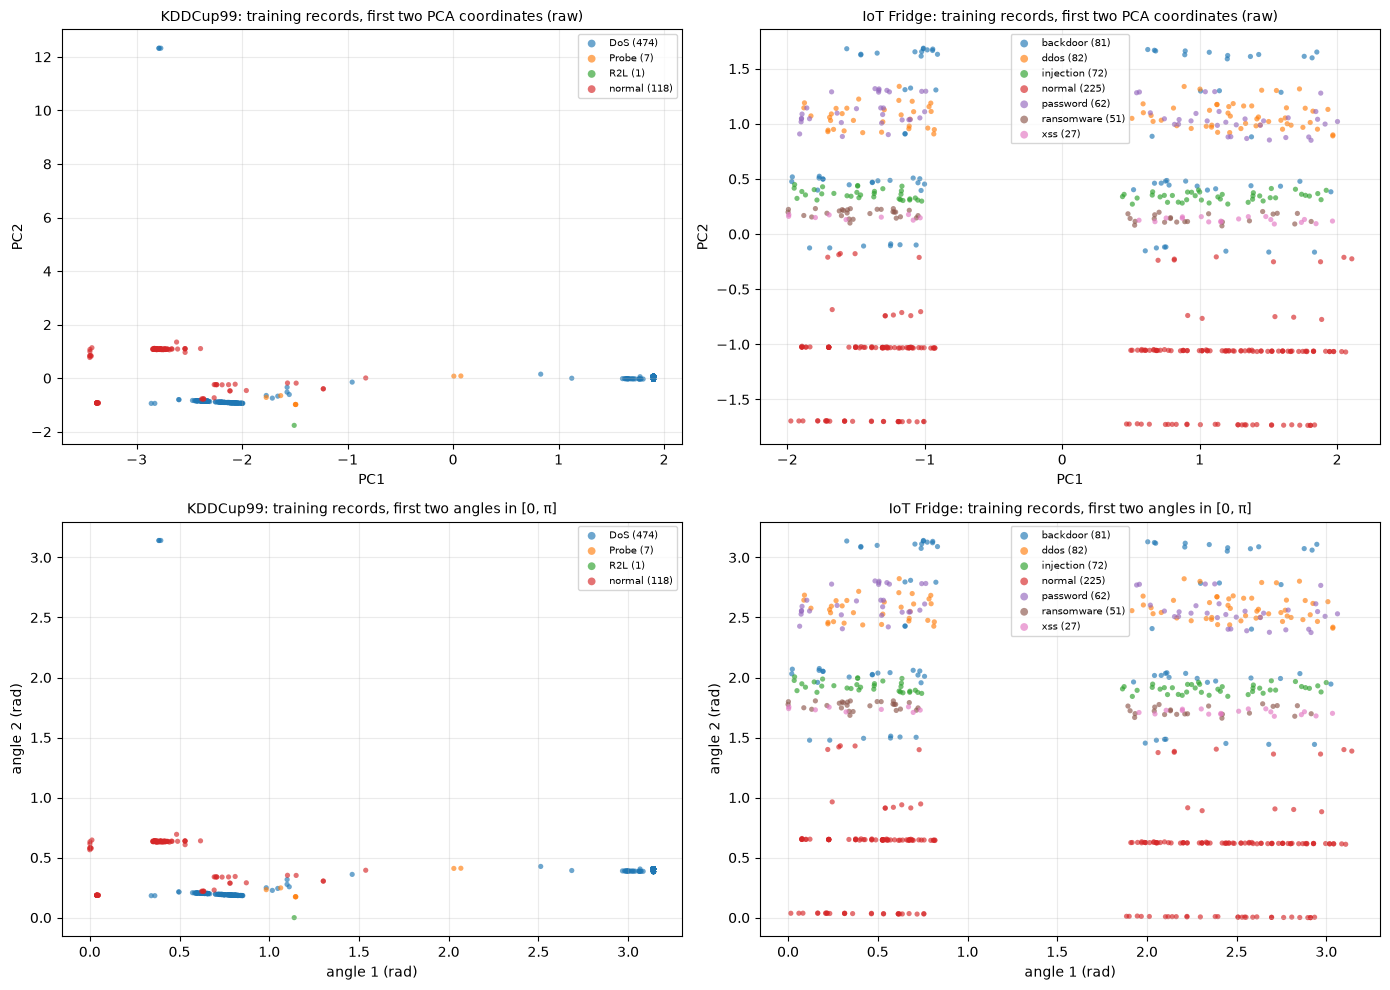

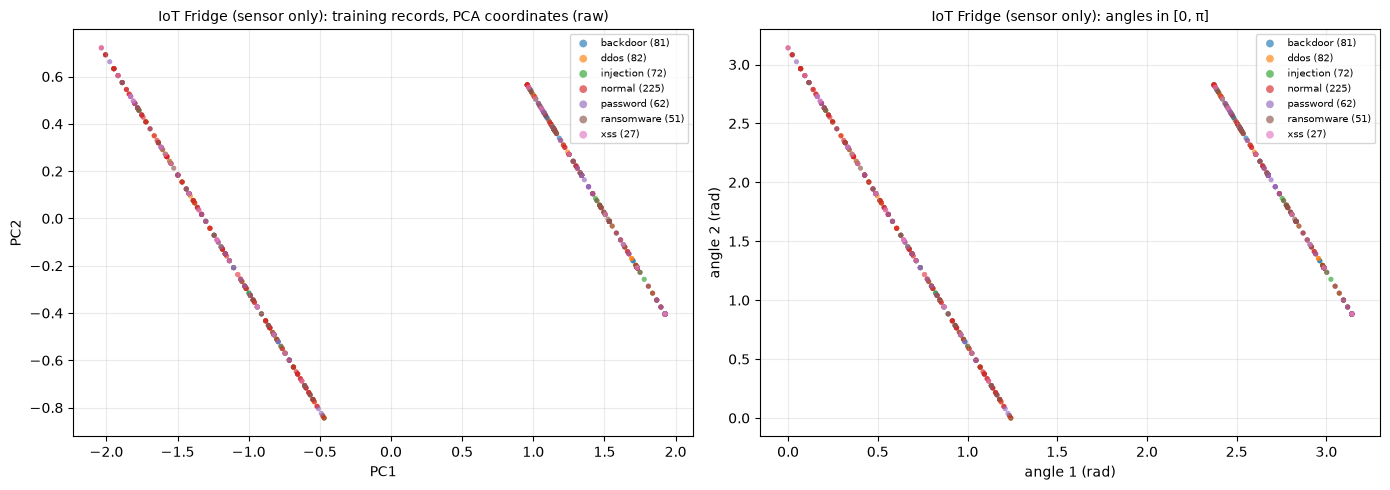

In [7]:
def scatter_groups(ax, XY, groups, title, xl, yl):
    cats = sorted(set(groups))
    cmap = plt.get_cmap("tab10")
    for i, g in enumerate(cats):
        m = np.array(groups) == g
        ax.scatter(XY[m, 0], XY[m, 1], s=14, alpha=0.65, color=cmap(i % 10), label=f"{g} ({m.sum()})", edgecolors="none")
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=7, markerscale=1.5); ax.grid(alpha=0.25)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, name in enumerate(["KDDCup99", "IoT Fridge"]):
    P = PREP0[name]
    scatter_groups(axes[0, j], P["Ztr"], P["group_tr"], f"{name}: training records, first two PCA coordinates (raw)", "PC1", "PC2")
    scatter_groups(axes[1, j], P["Atr"], P["group_tr"], f"{name}: training records, first two angles in [0, π]", "angle 1 (rad)", "angle 2 (rad)")
plt.tight_layout(); plt.show()

# the sensor-only diagnostic uses just two features, hence a 2-qubit circuit
P = PREP0["IoT Fridge (sensor only)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter_groups(axes[0], P["Ztr"], P["group_tr"], "IoT Fridge (sensor only): training records, PCA coordinates (raw)", "PC1", "PC2")
scatter_groups(axes[1], P["Atr"], P["group_tr"], "IoT Fridge (sensor only): angles in [0, π]", "angle 1 (rad)", "angle 2 (rad)")
plt.tight_layout(); plt.show()

### What the pictures already say

* **KDDCup99** is dominated by attacks (DoS above all); the normal class is the 20 % minority. Whatever a model does, "predict attack
  for everything" scores about 80 %, which is exactly the 80.33 % the paper reports for the VQC (Table II).
* **IoT Fridge**: the sensor readings (`fridge_temperature`, `temp_condition`) of normal and attack records overlap completely in the
  scatter; the attack types differ in *when* they happened (the timestamp columns), not in what the sensor measured. The end of Section 7 quantifies this.

## 3. Classical baselines on the same inputs

For every dataset and seed we train, on exactly the quantum model's 4 (or 2) angle inputs and also on all selected standardised features:

* **majority class** (the number any useful model must beat when classes are imbalanced),
* `RandomForestClassifier(200)` and `SVC(kernel="rbf")`,
* a small **MLP autoencoder** (8-3-8 hidden units, scikit-learn) trained on *normal* training records only; a record is flagged as an
  attack when its reconstruction error exceeds the 95th percentile of the training-normal errors. This is our stand-in for the
  paper's LSTM autoencoder (Table IV): same anomaly-detection principle, but not recurrent, and no TensorFlow is needed.

Metrics follow the paper (accuracy) and add balanced accuracy, precision, recall and F1 with the attack as the positive class.

In [8]:
def metrics(y, p):
    return dict(acc=100 * accuracy_score(y, p), bal_acc=100 * balanced_accuracy_score(y, p),
                prec=precision_score(y, p, zero_division=0), rec=recall_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0))

def run_classical(P):
    out = {}
    seed = P["seed"]
    maj = int(np.round(P["ytr"].mean()))
    out["Majority class"] = (np.full(len(P["yte"]), maj), 0.0)
    for tag, (Xtr, Xte) in {"4 angles" if P["n_q"] == 4 else f"{P['n_q']} angles": (P["Atr"], P["Ate"]), "all features": (P["Ftr"], P["Fte"])}.items():
        for mname, model in [("RandomForest", RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=1)),
                             ("SVC (rbf)", SVC(kernel="rbf", C=1.0, random_state=seed))]:
            t0 = time.perf_counter(); model.fit(Xtr, P["ytr"]); pred = model.predict(Xte)
            out[f"{mname} [{tag}]"] = (pred, time.perf_counter() - t0)
    # MLP autoencoder on normal training records, all selected features
    t0 = time.perf_counter()
    ae_sc = StandardScaler().fit(P["Ftr"][P["ytr"] == 0])                            # the detector sees normal records only, scaling included
    normal, F_te = ae_sc.transform(P["Ftr"][P["ytr"] == 0]), ae_sc.transform(P["Fte"])
    ae = MLPRegressor(hidden_layer_sizes=(8, 3, 8), activation="tanh", max_iter=400, random_state=seed).fit(normal, normal)   # CHOICE: tiny AE
    err = lambda F: ((ae.predict(F) - F) ** 2).mean(axis=1)
    thr = np.percentile(err(normal), AE_PERCENTILE)
    out["MLP autoencoder (stand-in for LSTM AE)"] = ((err(F_te) > thr).astype(int), time.perf_counter() - t0)
    return out

## Quantum Circuit Architecture

Both quantum models are built here and the circuits that will be executed are drawn from the very objects used later.

**VQC.** `VQC(feature_map, ansatz, optimizer, sampler)` of `qiskit-machine-learning`: a Pauli feature map (Hadamards, `P(2x)` rotations and
`ZZ` couplings between neighbouring qubits, repeated twice) encodes the angles, a `RealAmplitudes` ansatz (RY layers with CNOT
entanglement) holds the trainable weights, all qubits are measured and the 2^n outcomes are mapped to the two classes by parity.
The paper does not specify the ansatz; depth and entanglement are our choices.

**UU† circuit.** The same Pauli feature map `U(x)` is applied to `|0...0>`, followed by the inverse feature map `U†(c)` of a
centroid `c`; the probability of measuring `0...0` equals `|<φ(c)|φ(x)>|^2`, the overlap of the two encoded states. There are **no
trainable parameters**; the "training" is the k-means step. A plain RY angle-encoding variant of `U` is also run and drawn.
For the 2-feature sensor-only diagnostic the same circuits are built with 2 qubits.

--- VQC, 4 qubits ---
qubits 4 | depth (decomposed) 29 | trainable weights 16 | input parameters 4 | gate counts {'u': 38, 'cx': 21}


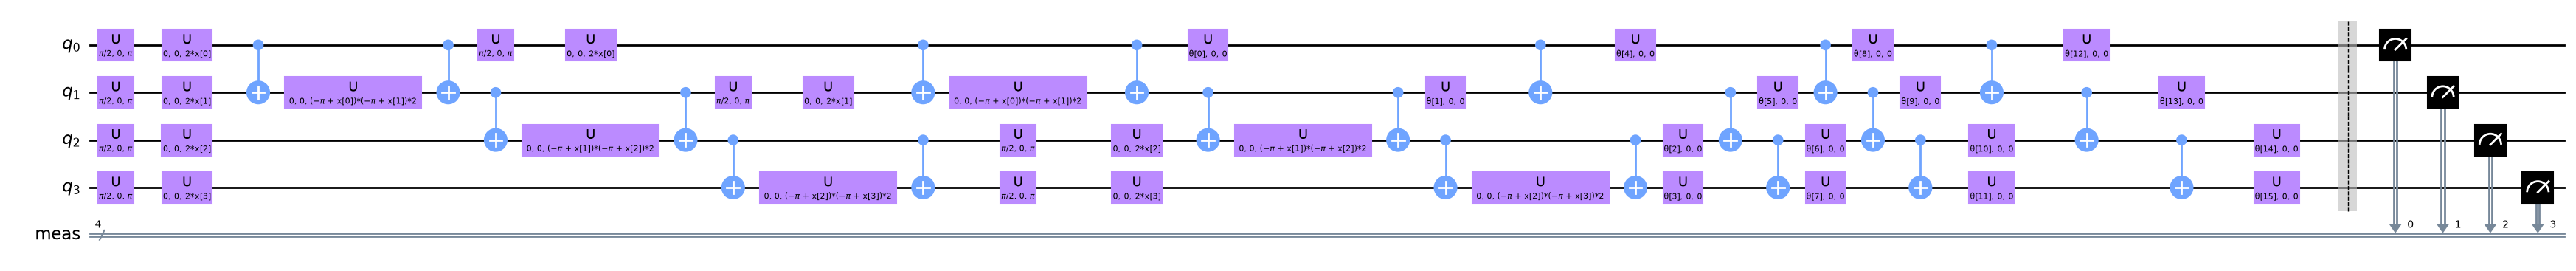

--- UU† (pauli encoding), 4 qubits ---
qubits 4 | depth 39 | trainable parameters 0 | data parameters 8 (x: 4, centroid c: 4)


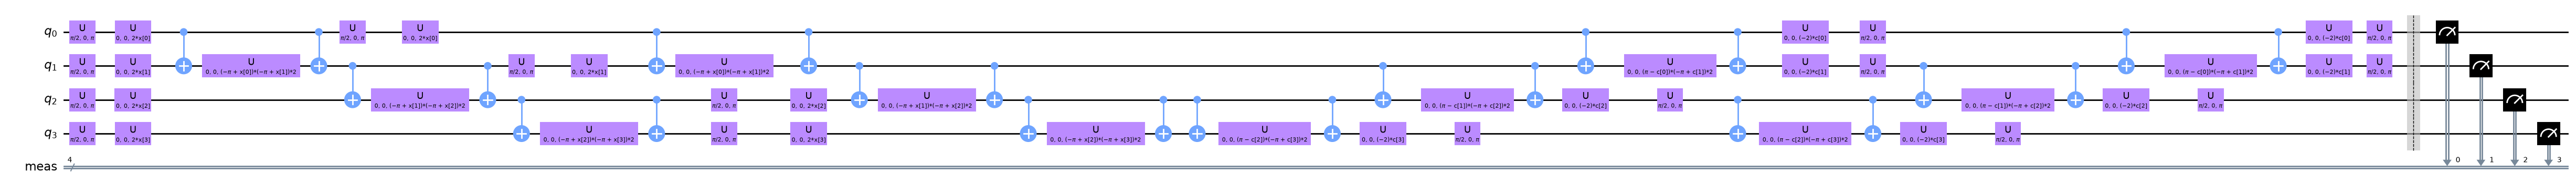

--- UU† (angle encoding), 4 qubits ---
qubits 4 | depth 3 | trainable parameters 0 | data parameters 8 (x: 4, centroid c: 4)


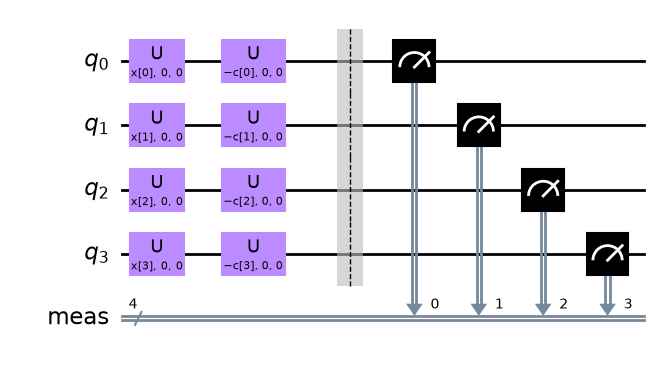

--- VQC, 2 qubits ---
qubits 2 | depth (decomposed) 17 | trainable weights 8 | input parameters 2 | gate counts {'u': 18, 'cx': 7}


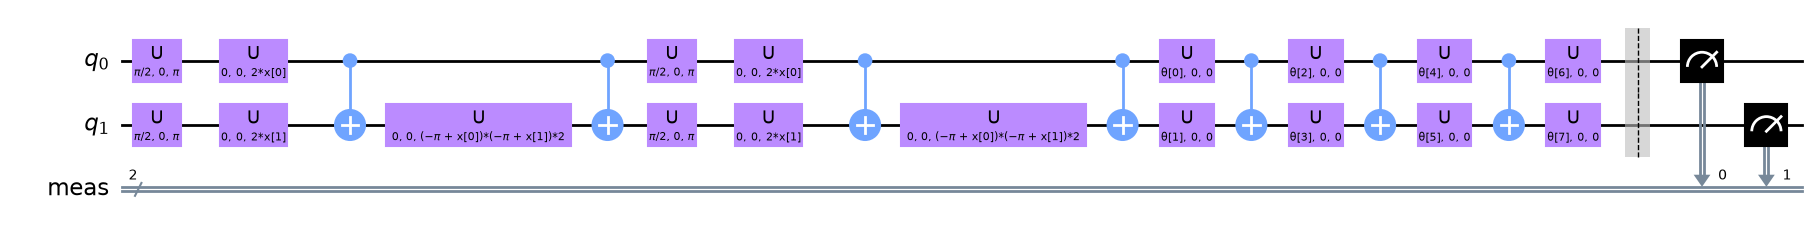

--- UU† (pauli encoding), 2 qubits ---
qubits 2 | depth 21 | trainable parameters 0 | data parameters 4 (x: 2, centroid c: 2)


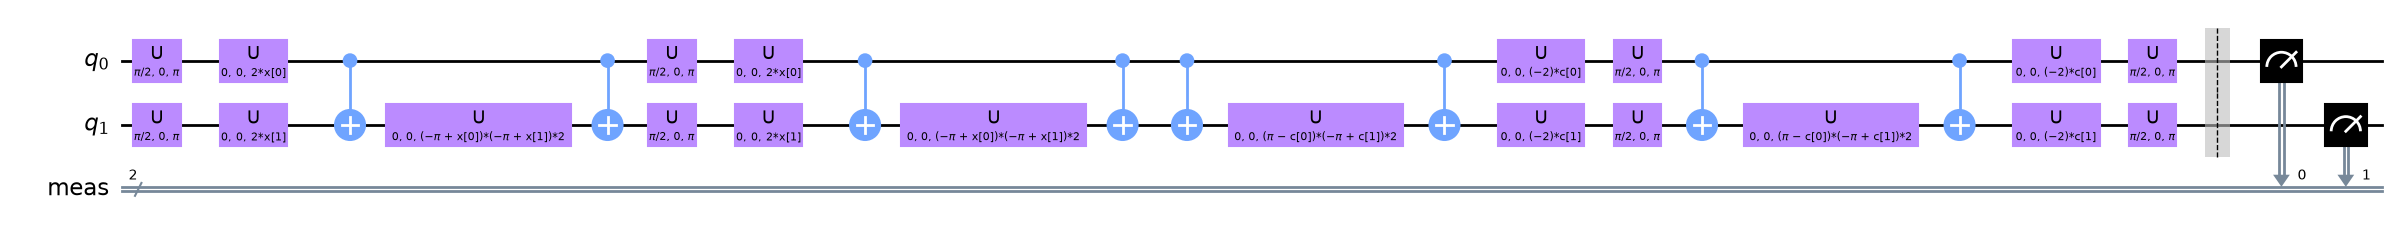

--- UU† (angle encoding), 2 qubits ---
qubits 2 | depth 3 | trainable parameters 0 | data parameters 4 (x: 2, centroid c: 2)


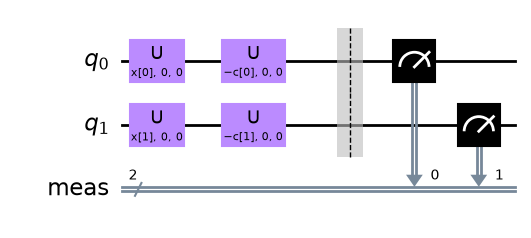

,model,qubits,depth,trainable
0,VQC,4,29,16
1,UU† (pauli),4,39,0
2,UU† (angle),4,3,0
3,VQC,2,17,8
4,UU† (pauli),2,21,0
5,UU† (angle),2,3,0


In [9]:
# ---------- circuit builders (the same functions are used for training / inference below) ----------
def fmap(n_q, prefix="x"):
    # CHOICE: Pauli feature map with Z and ZZ terms; the paper only says "Pauli-based feature maps"
    return pauli_feature_map(n_q, reps=VQC_FM_REPS, paulis=["Z", "ZZ"], entanglement="linear", parameter_prefix=prefix)

def angle_map(n_q, prefix="x"):
    p = ParameterVector(prefix, n_q); qc = QuantumCircuit(n_q)
    for i in range(n_q): qc.ry(p[i], i)                 # plain angle encoding (RY rotations)
    return qc

def uu_circuit(n_q, kind="pauli", measure=True):
    """U(x) followed by U(c)^dagger, then measurement of all qubits. 2*n_q input parameters: x and c."""
    mk = fmap if kind == "pauli" else angle_map
    qc = QuantumCircuit(n_q)
    qc.compose(mk(n_q, "x"), inplace=True)
    qc.compose(mk(n_q, "c").inverse(), inplace=True)
    if measure: qc.measure_all()
    return qc

def make_vqc(n_q, maxiter, callback=None, seed=SEED):
    return VQC(feature_map=fmap(n_q), ansatz=real_amplitudes(n_q, reps=VQC_ANSATZ_REPS, entanglement="linear"),
               optimizer=COBYLA(maxiter=maxiter), sampler=AerSampler(default_shots=SHOTS_VQC, seed=seed), callback=callback)

arch_rows = []
for n_q in sorted({P["n_q"] for P in PREP0.values()}, reverse=True):
    vqc_demo = make_vqc(n_q, 1)
    circ = vqc_demo.neural_network.circuit                      # exactly the circuit the sampler executes (before measurement)
    full = circ.copy(); full.measure_all()
    print(f"--- VQC, {n_q} qubits ---")
    print(f"qubits {circ.num_qubits} | depth (decomposed) {circ.decompose(reps=3).depth()} | trainable weights {vqc_demo.neural_network.num_weights}"
          f" | input parameters {vqc_demo.neural_network.num_inputs} | gate counts {dict(circ.decompose(reps=3).count_ops())}")
    display(full.decompose(reps=2).draw("mpl", fold=-1, style="clifford"))
    arch_rows.append(dict(model="VQC", qubits=n_q, depth=circ.decompose(reps=3).depth(), trainable=vqc_demo.neural_network.num_weights))
    for kind in ["pauli", "angle"]:
        uu = uu_circuit(n_q, kind)
        flat = uu.decompose(reps=3)
        print(f"--- UU† ({kind} encoding), {n_q} qubits ---")
        print(f"qubits {uu.num_qubits} | depth {flat.depth()} | trainable parameters 0 | data parameters {uu.num_parameters} (x: {n_q}, centroid c: {n_q})")
        display(uu.decompose(reps=2).draw("mpl", fold=-1, style="clifford"))
        arch_rows.append(dict(model=f"UU† ({kind})", qubits=n_q, depth=flat.depth(), trainable=0))
display(pd.DataFrame(arch_rows))

### How the circuits are simulated, and a sanity check

Thousands of circuit evaluations are needed (every test record against every centroid, every objective evaluation of the VQC). The Aer
sampler primitive binds parameters record by record in Python and is far too slow for that on a CPU, so the circuits are run as one batch on
the **Aer state-vector simulator** (`parameter_binds`): the simulator returns the exact outcome distribution of the *measured circuit*
(the measurement is replaced by `save_probabilities`, which does not change the gates), and the shots are then drawn from that distribution
(binomial sampling, which is what an ideal measurement of `shots` repetitions gives). The cell below checks the pipeline in three ways:
against an independent state-vector computation of `|<φ(c)|φ(x)>|²`, against the Aer *sampler primitive* running the real measured circuit, and
for the shot noise of the 100-shot readout.

In [10]:
class AerDist:
    """Exact outcome distributions of a parametrised circuit (no measurements) for many parameter sets, from the Aer state-vector simulator."""
    SIM = AerSimulator(method="statevector")
    def __init__(self, circ):
        self.names = [p.name for p in circ.parameters]
        qc = circ.copy(); qc.save_probabilities()
        self.tq = transpile(qc, self.SIM, optimization_level=1, seed_transpiler=SEED)
        self.cols = [self.names.index(p.name) for p in self.tq.parameters]
    def probs(self, vals, chunk=1500):
        out = []
        for s in range(0, len(vals), chunk):
            ch = vals[s:s + chunk]
            res = self.SIM.run(self.tq, parameter_binds=[{p: ch[:, c] for p, c in zip(self.tq.parameters, self.cols)}]).result()
            out.append(np.array([res.data(i)["probabilities"] for i in range(len(ch))]))
        return np.vstack(out)

_UU_DIST = {}
def uu_p0_exact(n_q, kind, A, C):
    """Exact P(0...0) of the UU† circuit for every (record, centroid) pair, shape (len(A), len(C))."""
    if (n_q, kind) not in _UU_DIST: _UU_DIST[(n_q, kind)] = AerDist(uu_circuit(n_q, kind, measure=False))
    d = _UU_DIST[(n_q, kind)]; N, K = len(A), len(C)
    A_rep, C_tile = np.repeat(A, K, axis=0), np.tile(C, (N, 1))
    vals = np.zeros((N * K, len(d.names)))                           # columns follow circuit.parameters (sorted by name: c[..] before x[..])
    for col, name in enumerate(d.names):
        idx = int(name.split("[")[1].rstrip("]"))
        vals[:, col] = A_rep[:, idx] if name.startswith("x") else C_tile[:, idx]
    return np.clip(np.nan_to_num(d.probs(vals)[:, 0]), 0.0, 1.0).reshape(N, K)      # clip float round-off (1 + 1e-16)

def uu_probs_shots(n_q, kind, A, C, shots, seed):
    """P(0...0) estimated from `shots` measurements, for every (record, centroid) pair."""
    p0 = uu_p0_exact(n_q, kind, A, C)
    return np.random.default_rng(seed).binomial(shots, p0) / shots

def uu_probs_exact(n_q, kind, A, C):
    mk = fmap if kind == "pauli" else angle_map
    base = mk(n_q, "x")
    sv = lambda v: Statevector(base.assign_parameters(dict(zip(base.parameters, v)))).data
    SA, SC = np.array([sv(a) for a in A]), np.array([sv(c) for c in C])
    return np.abs(SA.conj() @ SC.T) ** 2                  # |<phi(a)|phi(c)>|^2

chk_rng = np.random.default_rng(SEED)
for kind in ["pauli", "angle"]:
    A, C = chk_rng.uniform(0, np.pi, (40, 4)), chk_rng.uniform(0, np.pi, (2, 4))
    p_aer, p_sv = uu_p0_exact(4, kind, A, C), uu_probs_exact(4, kind, A, C)
    print(f"{kind:6s}: max |Aer batch - independent state-vector overlap| = {np.abs(p_aer - p_sv).max():.2e}, mean overlap {p_sv.mean():.3f}")
    assert np.abs(p_aer - p_sv).max() < 1e-8, "batched Aer run disagrees with |<phi(c)|phi(x)>|^2"
    # the real measured circuit on the Aer SAMPLER primitive, 6 (record, centroid) pairs, 20000 shots
    qc = uu_circuit(4, kind); k = 0
    vals = np.zeros((6, qc.num_parameters))
    for col, p in enumerate(qc.parameters):
        idx = int(p.name.split("[")[1].rstrip("]")); vals[:, col] = (A[:6, idx] if p.name.startswith("x") else C[0, idx])
    ba = AerSampler(default_shots=20000, seed=SEED).run([(qc, vals)]).result()[0].data.meas
    p_primitive = (ba.array == 0).all(axis=-1).mean(axis=-1)
    print(f"{'':6s}  Aer sampler primitive on the measured circuit vs exact: max diff {np.abs(p_primitive - p_aer[:6, 0]).max():.4f} (20000 shots)")
    assert np.abs(p_primitive - p_aer[:6, 0]).max() < 0.02
print("100-shot readout noise of a probability near 0.5 (standard error): %.3f" % np.sqrt(0.25 / SHOTS_UU))
print("the executed UU† circuit reproduces |<phi(c)|phi(x)>|^2")

pauli : max |Aer batch - independent state-vector overlap| = 2.28e-15, mean overlap 0.070


        Aer sampler primitive on the measured circuit vs exact: max diff 0.0029 (20000 shots)


angle : max |Aer batch - independent state-vector overlap| = 3.33e-16, mean overlap 0.257


        Aer sampler primitive on the measured circuit vs exact: max diff 0.0055 (20000 shots)
100-shot readout noise of a probability near 0.5 (standard error): 0.050
the executed UU† circuit reproduces |<phi(c)|phi(x)>|^2


## 4. The UU† classifier

For one dataset and seed:

1. `KMeans(2)` on the training angles gives two centroids; each takes the majority label of its training members (**the literal reading of the paper**: "k-means to find the
   centroids"). If both clusters are mostly attacks (as in the imbalanced data here) both centroids carry the label "attack" and the classifier can only answer "attack".
   Variants that avoid this: the two **class means**, and **per-class k-means** (3 centroids inside each class).
2. For every test record the circuit returns `P(0...0)` against each centroid with 100 shots.
3. The record gets the label of the centroid with the larger probability (ties broken at random).

There is nothing to optimise, so the "training time" is the k-means fit. Each variant is run with the Pauli feature map (reps 2, ZZ couplings) and with plain RY angle encoding.
The Pauli map with `ZZ` terms produces very small overlaps between different records (a "concentrated" kernel: the mean overlap in the check above is 0.07), which makes
a 100-shot readout noisy; the RY map is much smoother.

In [11]:
def centroids_for(P, how):
    A, y = P["Atr"], P["ytr"]
    if how == "kmeans":
        km = KMeans(n_clusters=2, n_init=10, random_state=P["seed"]).fit(A)
        lab = np.array([int(round(y[km.labels_ == k].mean())) if (km.labels_ == k).any() else 0 for k in range(2)])
        return km.cluster_centers_, lab
    if how == "perclass":                                                              # CHOICE: 3 k-means centroids inside each class
        cs, ls = [], []
        for k in (0, 1):
            Ak = A[y == k]; km = KMeans(n_clusters=min(3, len(Ak)), n_init=10, random_state=P["seed"]).fit(Ak)
            cs.append(km.cluster_centers_); ls += [k] * len(km.cluster_centers_)
        return np.vstack(cs), np.array(ls)
    return np.array([A[y == 0].mean(0), A[y == 1].mean(0)]), np.array([0, 1])          # class means

def run_uu(P, kind, how, shots=SHOTS_UU, exact=False):
    t0 = time.perf_counter()
    C, lab = centroids_for(P, how)
    prob = uu_p0_exact(P["n_q"], kind, P["Ate"], C) if exact else uu_probs_shots(P["n_q"], kind, P["Ate"], C, shots, P["seed"])
    r = np.random.default_rng(P["seed"]); prob = prob + 1e-9 * r.random(prob.shape)       # random tie-break
    return lab[prob.argmax(1)], time.perf_counter() - t0

# the first entry is the literal reading of the paper (k-means centroids of the unlabelled training data); the others are variants
UU_VARIANTS = {"UU† Pauli, k-means, 100 shots": ("pauli", "kmeans", False),
               "UU† Pauli, class means, 100 shots": ("pauli", "means", False),
               "UU† Pauli, per-class k-means, 100 shots": ("pauli", "perclass", False),
               "UU† RY angle, k-means, 100 shots": ("angle", "kmeans", False),
               "UU† RY angle, class means, 100 shots": ("angle", "means", False),
               "UU† RY angle, per-class k-means, 100 shots": ("angle", "perclass", False),
               "UU† Pauli, k-means, exact": ("pauli", "kmeans", True)}

## 5. The VQC

The VQC is trained with COBYLA for the paper's number of iterations (Table II: 10 for KDDCup99, 35 for IoT Fridge), using the
cross-entropy loss. For speed the training loop is our own thin `BatchedVQC` class around the circuit of a `qiskit-machine-learning` `VQC` object
(all records of one objective evaluation are simulated as one Aer batch instead of one job per record; parity decoding, cross-entropy loss and
the COBYLA optimiser are those of the library's VQC). A check right below shows that its sampled class probabilities equal the exact parity
probabilities of the drawn circuit. SciPy's COBYLA refuses fewer than `n_weights + 2` objective
evaluations (18 for our 16-weight ansatz) and raises small budgets to that minimum, so "10 iterations" really means 18 evaluations here; the number of
evaluations actually used is printed in the results. With `FAST_MODE = False` a second run with a 100-iteration budget shows what the
tiny budgets leave on the table. A callback records the loss after every objective evaluation.

In [12]:
class BatchedVQC:
    """The Qiskit VQC (same circuit, same parity decoding, same cross-entropy loss, same COBYLA) with a faster inner loop.

    qiskit-machine-learning's `VQC.fit` sends every training record to the sampler as a separate job; on a CPU that costs ~40 ms per
    record and evaluation. Here all records of one objective evaluation are simulated as ONE batch (the circuit with an array of
    parameter values on the Aer state-vector simulator, shots drawn from the outcome distribution; see the note before the UU† check).
    The circuit is taken from the library object `make_vqc(...)`, so what runs is the drawn circuit."""
    def __init__(self, n_q, maxiter, seed):
        self.lib = make_vqc(n_q, maxiter, seed=seed)                    # library VQC: supplies circuit, parameter order, weight count
        qnn = self.lib.neural_network
        self.dist = AerDist(qnn.circuit)                                # the VQC circuit (the measurement is the readout of the outcome distribution)
        self.in_idx = [self.dist.names.index(p.name) for p in qnn.input_params]; self.w_idx = [self.dist.names.index(p.name) for p in qnn.weight_params]
        self.n_w, self.maxiter, self.seed = qnn.num_weights, maxiter, seed
        self.odd = np.array([bin(i).count("1") % 2 for i in range(2 ** n_q)], dtype=bool)   # parity of every outcome bitstring
        self.rng = np.random.default_rng(seed)
        self.w = None; self.losses = []

    def class_probs(self, X, w, exact=False):
        """P(class 1) = probability that the measured bitstring has odd parity (Qiskit's default VQC decoding), estimated from SHOTS_VQC shots."""
        vals = np.zeros((len(X), len(self.dist.names))); vals[:, self.in_idx] = X; vals[:, self.w_idx] = w
        p1 = self.dist.probs(vals)[:, self.odd].sum(axis=1).clip(0, 1)
        if not exact: p1 = self.rng.binomial(SHOTS_VQC, p1) / SHOTS_VQC
        return np.stack([1 - p1, p1], axis=1)

    def fit(self, X, y):
        def loss(w):
            p = np.clip(self.class_probs(X, w), 1e-10, 1.0)
            l = float(-np.mean(np.log(p[np.arange(len(y)), y]))); self.losses.append(l); return l
        w0 = np.random.default_rng(self.seed).random(self.n_w)                              # CHOICE: random start in [0, 1), as the library does
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            self.w = COBYLA(maxiter=self.maxiter).minimize(loss, w0).x
        return self

    def predict(self, X):
        return (self.class_probs(X, self.w)[:, 1] > 0.5).astype(int)

def run_vqc(P, maxiter):
    m = BatchedVQC(P["n_q"], maxiter, P["seed"])
    t0 = time.perf_counter(); m.fit(P["Atr"], P["ytr"]); pred = m.predict(P["Ate"])
    return pred, time.perf_counter() - t0, m.losses

In [13]:
# Check: the sampled class probabilities of BatchedVQC equal the exact parity probabilities of the drawn circuit (state vector), up to shot noise
chk = BatchedVQC(4, 10, SEED)
Xc = np.random.default_rng(SEED).uniform(0, np.pi, (8, 4)); wc = np.random.default_rng(SEED + 1).random(chk.n_w)
p_sampled = chk.class_probs(Xc, wc)[:, 1]
qnn = chk.lib.neural_network
p_exact = []
for x in Xc:
    bind = dict(zip(qnn.input_params, x)); bind.update(dict(zip(qnn.weight_params, wc)))
    pr = Statevector(qnn.circuit.assign_parameters(bind)).probabilities()
    p_exact.append(sum(p for i, p in enumerate(pr) if bin(i).count("1") % 2 == 1))       # odd-parity outcomes = class 1
p_exact = np.array(p_exact)
p_batch_exact = chk.class_probs(Xc, wc, exact=True)[:, 1]
assert np.allclose(p_batch_exact, p_exact, atol=1e-8), "batched Aer run differs from the independent state-vector parity probabilities"
print("P(class 1) sampled :", np.round(p_sampled, 3)); print("P(class 1) exact   :", np.round(p_exact, 3))
print("max |sampled - exact| =", round(float(np.abs(p_sampled - p_exact).max()), 4), "(1024 shots: standard error about 0.015)")
assert np.abs(p_sampled - p_exact).max() < 0.08, "BatchedVQC does not compute the circuit's parity probabilities"

P(class 1) sampled : [0.617 0.764 0.618 0.619 0.402 0.379 0.561 0.398]
P(class 1) exact   : [0.608 0.741 0.61  0.608 0.398 0.366 0.583 0.412]
max |sampled - exact| = 0.0225 (1024 shots: standard error about 0.015)


## 6. Running everything

For each dataset and seed: classical baselines, the four UU† variants, the VQC at the paper's budget (and the extended budget in the
full run). Results are collected in one table; the confusion matrices and loss curves of the first seed are kept for plotting.

In [14]:
rows, preds0, loss0 = [], {}, {}
SEEDS = [SEED + 17 * i for i in range(N_SEEDS)]
t_all = time.time()
for name in DATASETS:
    for seed in SEEDS:
        P = PREP0[name] if seed == SEED else prepare(name, seed)
        results = dict(run_classical(P))
        for label, (kind, how, ex) in UU_VARIANTS.items():
            results[label] = run_uu(P, kind, how, exact=ex)
        it = VQC_ITERS[name]
        pred, secs, losses = run_vqc(P, it); results["VQC (paper budget)"] = (pred, secs)
        if seed == SEED: loss0[(name, it)] = losses
        if VQC_EXTRA_ITERS:
            pred2, secs2, losses2 = run_vqc(P, VQC_EXTRA_ITERS); results["VQC (extended budget)"] = (pred2, secs2)
            if seed == SEED: loss0[(name, VQC_EXTRA_ITERS)] = losses2
        for model, (pred, secs) in results.items():
            rows.append(dict(dataset=name, seed=seed, model=model, seconds=secs, **metrics(P["yte"], pred)))
            if seed == SEED: preds0[(name, model)] = (P["yte"], pred)
        print(f"{name:26s} seed {seed}: done ({time.time() - t_all:.0f} s elapsed; VQC objective evaluations used: {len(losses)})")
res = pd.DataFrame(rows)
print(f"total {time.time() - t_all:.0f} s")

KDDCup99                   seed 42: done (303 s elapsed; VQC objective evaluations used: 18)


KDDCup99                   seed 59: done (549 s elapsed; VQC objective evaluations used: 18)


KDDCup99                   seed 76: done (847 s elapsed; VQC objective evaluations used: 18)


IoT Fridge                 seed 42: done (1324 s elapsed; VQC objective evaluations used: 35)


IoT Fridge                 seed 59: done (1691 s elapsed; VQC objective evaluations used: 35)


IoT Fridge                 seed 76: done (2046 s elapsed; VQC objective evaluations used: 35)


IoT Fridge (sensor only)   seed 42: done (2212 s elapsed; VQC objective evaluations used: 35)


IoT Fridge (sensor only)   seed 59: done (2404 s elapsed; VQC objective evaluations used: 35)


IoT Fridge (sensor only)   seed 76: done (2635 s elapsed; VQC objective evaluations used: 35)
total 2635 s


## 7. Results (the notebook's version of Tables II to IV)

In [15]:
agg = (res.groupby(["dataset", "model"], sort=False)
          .agg(acc=("acc", "mean"), acc_std=("acc", "std"), bal_acc=("bal_acc", "mean"), f1=("f1", "mean"),
               prec=("prec", "mean"), rec=("rec", "mean"), seconds=("seconds", "mean")).round(3))
for name in DATASETS:
    print(f"\n=== {name}  (mean over {N_SEEDS} seeds; accuracy in %, F1/precision/recall with attack = positive) ===")
    display(agg.loc[name])


=== KDDCup99  (mean over 3 seeds; accuracy in %, F1/precision/recall with attack = positive) ===


,acc,acc_std,bal_acc,f1,prec,rec,seconds
model,,,,,,,
Majority class,80.300,0.000,50.000,0.891,0.803,1.000,0.000
RandomForest [4 angles],98.683,0.340,98.478,0.992,0.995,0.988,3.655
SVC (rbf) [4 angles],94.883,0.782,88.035,0.969,0.946,0.993,0.173
RandomForest [all features],99.383,0.419,99.393,0.996,0.999,0.994,3.608
SVC (rbf) [all features],97.583,1.255,96.388,0.985,0.986,0.984,0.104
MLP autoencoder (stand-in for LSTM AE),97.600,0.397,96.175,0.985,0.985,0.985,2.062
"UU† Pauli, k-means, 100 shots",80.300,0.000,50.000,0.891,0.803,1.000,12.902
"UU† Pauli, class means, 100 shots",40.350,33.484,52.355,0.391,0.629,0.325,13.244
"UU† Pauli, per-class k-means, 100 shots",94.867,2.411,89.972,0.969,0.957,0.980,33.655



=== IoT Fridge  (mean over 3 seeds; accuracy in %, F1/precision/recall with attack = positive) ===


,acc,acc_std,bal_acc,f1,prec,rec,seconds
model,,,,,,,
Majority class,62.450,0.000,50.000,0.769,0.624,1.000,0.000
RandomForest [4 angles],99.983,0.029,99.978,1.000,1.000,1.000,1.894
SVC (rbf) [4 angles],100.000,0.000,100.000,1.000,1.000,1.000,0.040
RandomForest [all features],100.000,0.000,100.000,1.000,1.000,1.000,2.610
SVC (rbf) [all features],100.000,0.000,100.000,1.000,1.000,1.000,0.042
MLP autoencoder (stand-in for LSTM AE),98.150,0.132,97.537,0.985,0.971,1.000,2.368
"UU† Pauli, k-means, 100 shots",62.450,0.000,50.000,0.769,0.624,1.000,16.373
"UU† Pauli, class means, 100 shots",46.867,2.458,46.699,0.525,0.596,0.474,12.714
"UU† Pauli, per-class k-means, 100 shots",56.017,2.838,56.273,0.610,0.683,0.552,51.969



=== IoT Fridge (sensor only)  (mean over 3 seeds; accuracy in %, F1/precision/recall with attack = positive) ===


,acc,acc_std,bal_acc,f1,prec,rec,seconds
model,,,,,,,
Majority class,62.450,0.000,50.000,0.769,0.624,1.000,0.000
RandomForest [2 angles],55.567,1.500,50.002,0.670,0.624,0.724,2.462
SVC (rbf) [2 angles],62.450,0.000,50.000,0.769,0.624,1.000,0.789
RandomForest [all features],55.650,1.481,50.042,0.671,0.625,0.726,3.429
SVC (rbf) [all features],62.450,0.000,50.000,0.769,0.624,1.000,0.523
MLP autoencoder (stand-in for LSTM AE),37.933,0.355,49.652,0.048,0.378,0.026,2.668
"UU† Pauli, k-means, 100 shots",62.450,0.000,50.000,0.769,0.624,1.000,8.098
"UU† Pauli, class means, 100 shots",50.200,0.737,50.368,0.555,0.628,0.497,6.963
"UU† Pauli, per-class k-means, 100 shots",51.533,0.929,51.046,0.577,0.634,0.530,21.512


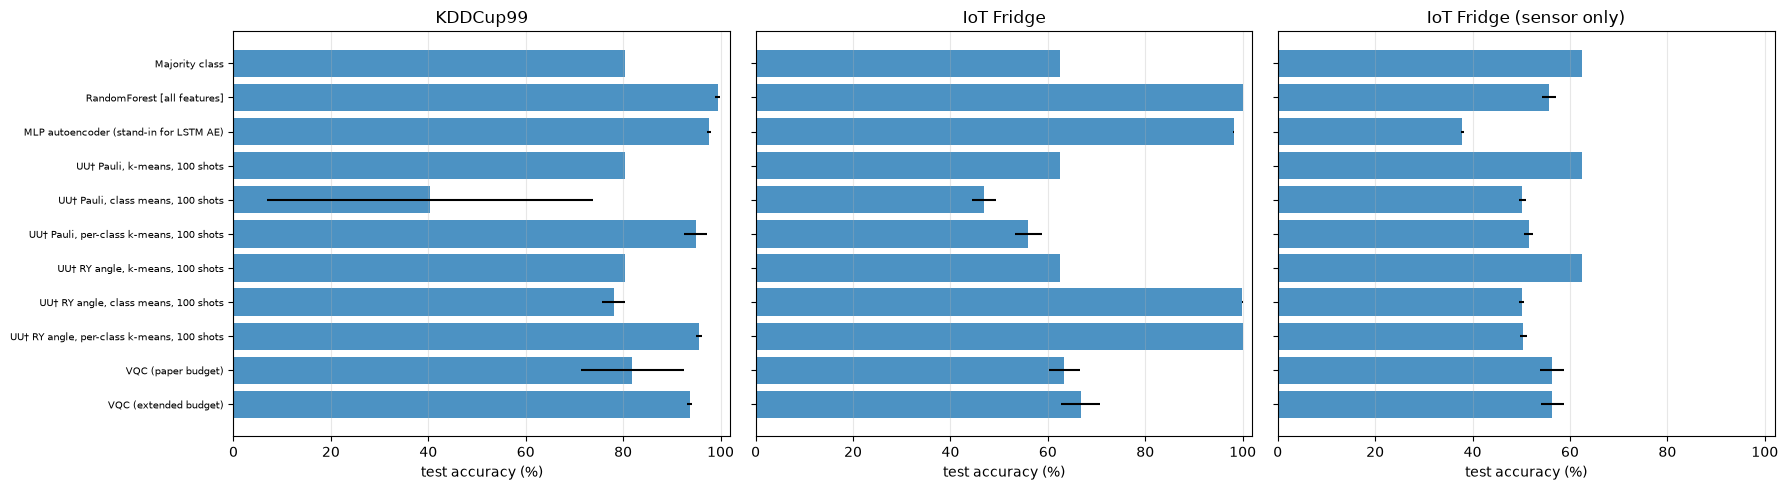

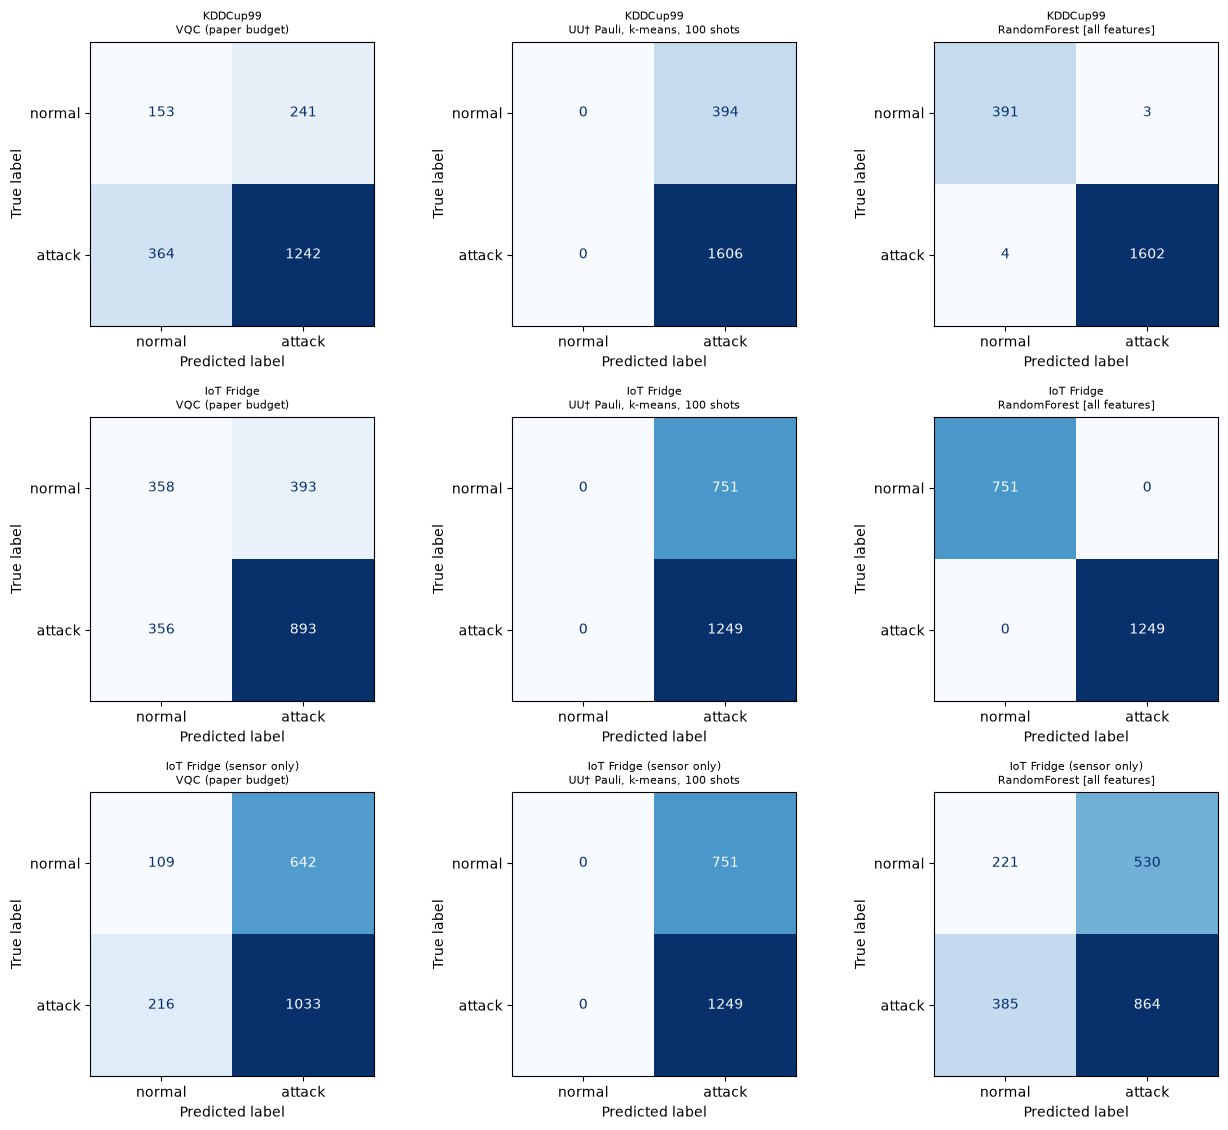

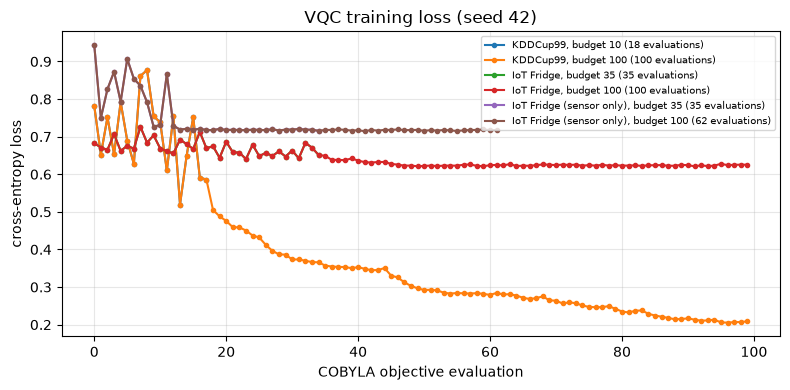

In [16]:
# Paper-style grouped bar chart (the paper's Fig. 5 is a radar chart of the same accuracies)
models_show = [m for m in agg.index.get_level_values(1).unique() if m.startswith(("Majority", "VQC (", "UU†", "RandomForest [all", "MLP")) and not m.endswith("exact")]
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, name in zip(axes, DATASETS):
    sub = agg.loc[name].loc[[m for m in models_show if m in agg.loc[name].index]]
    ax.barh(range(len(sub)), sub["acc"], xerr=sub["acc_std"].fillna(0), color="tab:blue", alpha=0.8)
    ax.set_yticks(range(len(sub))); ax.set_yticklabels(sub.index, fontsize=7); ax.invert_yaxis()
    ax.set_xlim(0, 102); ax.set_title(name); ax.set_xlabel("test accuracy (%)"); ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

# Confusion matrices (attack = positive class), first seed, for the main quantum models and the best classical one
fig, axes = plt.subplots(len(DATASETS), 3, figsize=(13, 3.8 * len(DATASETS)))
for i, name in enumerate(DATASETS):
    it = VQC_ITERS[name]
    for j, model in enumerate(["VQC (paper budget)", "UU† Pauli, k-means, 100 shots", "RandomForest [all features]"]):
        y, p = preds0[(name, model)]
        ConfusionMatrixDisplay(confusion_matrix(y, p, labels=[0, 1]), display_labels=["normal", "attack"]).plot(ax=axes[i, j], colorbar=False, cmap="Blues")
        axes[i, j].set_title(f"{name}\n{model}", fontsize=8)
plt.tight_layout(); plt.show()

# VQC loss curves (paper's callback, first seed)
fig, ax = plt.subplots(figsize=(8, 4))
for (name, it), l in loss0.items():
    ax.plot(l, marker="o", ms=3, label=f"{name}, budget {it} ({len(l)} evaluations)")
ax.set_xlabel("COBYLA objective evaluation"); ax.set_ylabel("cross-entropy loss"); ax.set_title("VQC training loss (seed 42)")
ax.legend(fontsize=7); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Why the IoT Fridge numbers look the way they do

The diagnostic below uses the full-size feature sets with a random forest (which can use any structure it finds): it shows what information
each feature group carries. If the timestamp alone gives ~100 % and the sensor readings alone give only the majority-class rate, then the
benchmark label is a function of *when* the record was captured, not of *what* the sensor measured.

In [17]:
d = DATASETS["IoT Fridge"]; y_all = d["y"]
Xf = d["X"].copy(); Xf["temp_condition"] = (Xf["temp_condition"] == "high").astype(int)
tr, te = train_test_split(np.arange(len(y_all)), test_size=0.3, stratify=y_all, random_state=SEED)
diag = []
for tag, cols in {"timestamp only (date, time)": ["date", "time"], "sensor only (temperature, condition)": ["fridge_temperature", "temp_condition"],
                  "all four columns": list(Xf.columns)}.items():
    rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1).fit(Xf.iloc[tr][cols], y_all[tr])
    diag.append(dict(inputs=tag, rf_test_accuracy=100 * rf.score(Xf.iloc[te][cols], y_all[te])))
diag.append(dict(inputs="majority class", rf_test_accuracy=100 * max(y_all[te].mean(), 1 - y_all[te].mean())))
display(pd.DataFrame(diag).round(2))
by_type = fr_raw.assign(stamp=stamp).groupby("type")["stamp"].agg(["min", "max", "count"])
display(by_type)

,inputs,rf_test_accuracy
0,"timestamp only (date, time)",100.00
1,"sensor only (temperature, condition)",62.45
2,all four columns,100.00
3,majority class,62.45


,min,max,count
type,,,
backdoor,2019-04-28 06:59:38,2019-04-29 01:13:08,5000
ddos,2019-04-25 14:42:33,2019-04-25 19:41:51,5000
injection,2019-04-25 07:49:13,2019-04-25 09:53:32,5000
normal,2019-03-31 12:36:52,2019-04-02 04:04:17,15000
password,2019-04-26 13:39:50,2019-04-26 18:28:38,5000
ransomware,2019-04-28 03:54:29,2019-04-28 05:27:25,2902
xss,2019-04-27 04:57:40,2019-04-27 05:40:53,2042


## 8. Side by side with the paper

Rule (from the project brief): a claim is **reproduced** if our mean accuracy is within 2 points of the paper's, otherwise **not reached**
(ours lower) or **exceeded** (ours higher) with the gap; **cannot be checked** when the data or the model are not available here.

In [18]:
def verdict(paper, ours, tol=2.0):
    if ours is None: return "cannot be checked"
    gap = ours - paper
    return "reproduced" if abs(gap) <= tol else (f"exceeded (+{gap:.1f})" if gap > 0 else f"not reached ({gap:.1f})")

def acc(name, model):
    s = agg.loc[(name, model), "acc"] if (name, model) in agg.index else None
    return None if s is None else float(s)

def best_of(name, prefixes, shots_only=False):
    sub = agg.loc[name]; sub = sub[[m.startswith(prefixes) and (not shots_only or "100 shots" in m) for m in sub.index]]
    return float(sub["acc"].max()), sub["acc"].idxmax()

claims = []
for name, p_vqc, p_uu, p_cl in [("KDDCup99", 80.33, 83.36, 97.37), ("IoT Fridge", 58.00, 55.33, 84.79)]:
    it = VQC_ITERS[name]
    claims += [dict(claim=f"{name}: VQC accuracy (Table II, {it} iterations)", paper=p_vqc, notebook=acc(name, "VQC (paper budget)")),
               dict(claim=f"{name}: UU† accuracy (Table III, 100 shots)", paper=p_uu, notebook=acc(name, "UU† Pauli, k-means, 100 shots")),
               dict(claim=f"{name}: UU† accuracy (Table III), best of our 100-shot UU† variants: {best_of(name, ('UU†',), shots_only=True)[1].replace(', 100 shots', '')}",
                    paper=p_uu, notebook=best_of(name, ("UU†",), shots_only=True)[0]),
               dict(claim=f"{name}: classical LSTM-AE accuracy (Table IV) vs our MLP autoencoder", paper=p_cl, notebook=acc(name, "MLP autoencoder (stand-in for LSTM AE)")),
               dict(claim=f"{name}: classical LSTM-AE accuracy (Table IV) vs our best classical model", paper=p_cl, notebook=best_of(name, ("RandomForest", "SVC"))[0])]
for ds_, key, pv in [("Environmental Sensor Telemetry", "VQC 65.65 / UU† 96.08 / LSTM-AE 94.99", None), ("TWTDUS", "VQC 73.00 / UU† 99.62 / LSTM-AE 94.96", None),
                     ("anoML-IoT", "VQC 92.00 / UU† 82.03 / LSTM-AE 94.94", None)]:
    claims.append(dict(claim=f"{ds_}: {key}", paper=np.nan, notebook=None))
comp = pd.DataFrame(claims)
comp["verdict"] = [verdict(p, n) if not np.isnan(p) else "cannot be checked" for p, n in zip(comp["paper"], comp["notebook"])]
comp["note"] = ""
comp.loc[comp.claim.str.startswith(("Environmental", "TWTDUS", "anoML")), "note"] = "dataset without public labelled copy (see 'which datasets can be run')"
comp["notebook"] = pd.to_numeric(comp["notebook"]).round(2)
pd.set_option("display.max_colwidth", 110); display(comp)

# structural claims
print("\nStructural claims")
for name in ["KDDCup99", "IoT Fridge"]:
    it = VQC_ITERS[name]
    q_best = max(float(v) for m, v in agg.loc[name, "acc"].items() if m.startswith(("VQC (", "UU†")) and not m.endswith("exact"))
    c_best, c_name = best_of(name, ("RandomForest", "SVC", "MLP"))
    maj = acc(name, "Majority class")
    print(f"- {name}: best quantum {q_best:.2f} % | best classical {c_best:.2f} % ({c_name}) | majority class {maj:.2f} %")
    print(f"    'classical models achieve higher accuracy than the quantum ones' -> " + ("reproduced" if c_best >= q_best else "not reproduced here"))
    print(f"    'VQC {acc(name, 'VQC (paper budget)'):.2f} % is above the majority-class rate {maj:.2f} %' -> " +
          ("yes" if acc(name, "VQC (paper budget)") > maj + 1 else "no: the VQC is at or below what predicting the majority class gives"))

,claim,paper,notebook,verdict,note
0,"KDDCup99: VQC accuracy (Table II, 10 iterations)",80.33,81.90,reproduced,
1,"KDDCup99: UU† accuracy (Table III, 100 shots)",83.36,80.30,not reached (-3.1),
2,"KDDCup99: UU† accuracy (Table III), best of our 100-shot UU† variants: UU† RY angle, per-class k-means",83.36,95.63,exceeded (+12.3),
3,KDDCup99: classical LSTM-AE accuracy (Table IV) vs our MLP autoencoder,97.37,97.60,reproduced,
4,KDDCup99: classical LSTM-AE accuracy (Table IV) vs our best classical model,97.37,99.38,exceeded (+2.0),
5,"IoT Fridge: VQC accuracy (Table II, 35 iterations)",58.00,63.40,exceeded (+5.4),
6,"IoT Fridge: UU† accuracy (Table III, 100 shots)",55.33,62.45,exceeded (+7.1),
7,"IoT Fridge: UU† accuracy (Table III), best of our 100-shot UU† variants: UU† RY angle, per-class k-means",55.33,100.00,exceeded (+44.7),
8,IoT Fridge: classical LSTM-AE accuracy (Table IV) vs our MLP autoencoder,84.79,98.15,exceeded (+13.4),
9,IoT Fridge: classical LSTM-AE accuracy (Table IV) vs our best classical model,84.79,100.00,exceeded (+15.2),



Structural claims
- KDDCup99: best quantum 95.63 % | best classical 99.38 % (RandomForest [all features]) | majority class 80.30 %
    'classical models achieve higher accuracy than the quantum ones' -> reproduced
    'VQC 81.90 % is above the majority-class rate 80.30 %' -> yes
- IoT Fridge: best quantum 100.00 % | best classical 100.00 % (SVC (rbf) [4 angles]) | majority class 62.45 %
    'classical models achieve higher accuracy than the quantum ones' -> reproduced
    'VQC 63.40 % is above the majority-class rate 62.45 %' -> no: the VQC is at or below what predicting the majority class gives


## 9. Reading the paper critically

* **Majority-class accuracy.** 80.3 % of the KDDCup99 10 % file are attacks, and the VQC's 80.33 % in the paper is what a classifier gets by saying "attack"
  every time (the literal k-means reading of the UU† circuit below collapses to exactly that row). On imbalanced data accuracy alone cannot separate a model that learned
  from one that learned nothing; the paper reports no precision, recall, F1, balanced accuracy or confusion matrix, and no majority-class baseline.
* **The IoT Fridge label depends on the clock, not on the sensor.** In the public labelled subset, normal records come from 31 March - 2 April 2019
  and each attack type from its own few hours (table in Section 7). The timestamp alone gives ~100 %, the sensor readings alone give the
  majority-class rate. The paper's 58.00 % (VQC) and 55.33 % (UU†) are *below* the 62 % majority rate of this subset, which suggests that the two quantum models extracted
  nothing useful from the inputs they were given. A good result on this data would be a sign of leakage through time, not of anomaly detection.
* **The UU† result depends on an unreported choice.** Which centroids are used decides everything: with two unlabelled k-means centroids the classifier can collapse to the
  majority class, whereas class means or per-class k-means centroids give very different accuracies (the Section 7 table lists all variants). The paper gives one number per dataset and does not
  say how the centroids were turned into class labels.
* **The UU† circuit is a nearest-centroid classifier.** Nothing is trained besides k-means, and the circuit computes a fixed state overlap that a
  classical computer evaluates in closed form (we did this as a check). It is a quantum *kernel* evaluation with two reference points, not a trained quantum model, and
  "exponential speed-up" or "massive parallelism" do not follow from it on 4 qubits.
* **Missing details.** Qubit count, number of training and test records, ansatz depth, train/test split, seeds, how the "Environmental Sensor" and
  "TWTDUS" datasets (which carry no ready-made attack label) were labelled, and the hyper-parameters of the classical LSTM autoencoders
  (Table IV values are quoted from other work, not re-run) are not given. Table I also lists 59,945 Fridge records and 494,020 KDDCup99 records;
  the public labelled Fridge subset has 39,944.
* **Iteration budgets chosen after the fact.** "The number of training iterations was selected based on convergence behaviour" while accuracy is read on
  the test set; a budget of 10 COBYLA iterations (objective evaluations) is smaller than the 17 evaluations COBYLA needs just to build its initial simplex for the 16 weights of
  our ansatz (SciPy silently raises it to 18), so the 10-iteration VQC is hardly trained at all. The loss curves above show it.
* **Scalability claims are not tested.** The classical-bottleneck heat-map (Fig. 4) and the radar diagram (Fig. 5) contain no quantum timings; all quantum runs are
  classical simulations of 4 qubits, which cannot show scaling.

## 10. Exercises

1. Raise `N_TRAIN` and `N_TEST` (for example to 2000 / 5000) and rerun the KDDCup99 VQC. Does the accuracy move away from the majority-class rate?
2. Change the VQC ansatz to `efficient_su2` or increase `VQC_ANSATZ_REPS`; how do the loss curve and the accuracy change at 10 and at 100 iterations?
3. Replace the UU† centroids by `KMeans(n_clusters=4)` per class (take the label of the nearest of 8 centroids). Is the quantum overlap better than the Euclidean
   nearest-centroid rule on the same angles (write that classical rule and compare)?
4. Split IoT Fridge **by time** (train on the earlier days, test on the later ones) instead of at random. What happens to the random forest on the timestamp columns?
5. Balance KDDCup99 (half normal, half attack) before sampling and recompute accuracy, balanced accuracy and F1 for all models. Which conclusions of Section 8 survive?